## Oppgave 2

In [66]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt
import random as rand


In [67]:
# Konstanter
beta=1 # Ikke nødvendig å inkludere k setter bare beta lik 1
h=1
max_t=100
num_par=101

Her har vi definert sannsynlighets utrykkene. Trenger ikke den siste fordi sannsynlighetene skal summeres til 1. 

In [68]:
def pp(x,V):
    p = 1/(1+np.exp(-beta*(V(x-1)-V(x+1)))+np.exp(-beta*(V(x)-V(x+1))))
    return p
    
def pm(x,V):
    p = 1/(1+np.exp(-beta*(V(x+1)-V(x-1)))+np.exp(-beta*(V(x)-V(x-1))))
    return p

Her tar random_step funksjonen inn en partikkel posisjon og bestemmer om den beveger seg til venstre eller høyre. 

In [69]:
def random_step(x,h,V):
    r= rand.random()
    if (r<pm(x,V)):
        return -1
    elif (r>1-pp(x,V)):
        return 1
    else:
        return 0

In [70]:
def simulation(start_pos,max_t,h, V):
    pos=np.array(start_pos)
    for i in range(max_t):
        for j in range(0,np.size(pos)):
            pos[j]+=random_step(pos[j],h,V)
    return pos

def multiSim(N,start_pos,max_t,h, V):
    totPos=np.array([])
    for i in range(N):
        pos = simulation(start_pos,max_t,h, V)
        totPos=np.concat((totPos,pos))
    return totPos

### oppgave 2a

 i)

In [71]:
def V(x):
    return 1
start_pos=np.arange(-50,51,h)
posisjoner_ai= multiSim(100,start_pos,max_t,h,V)


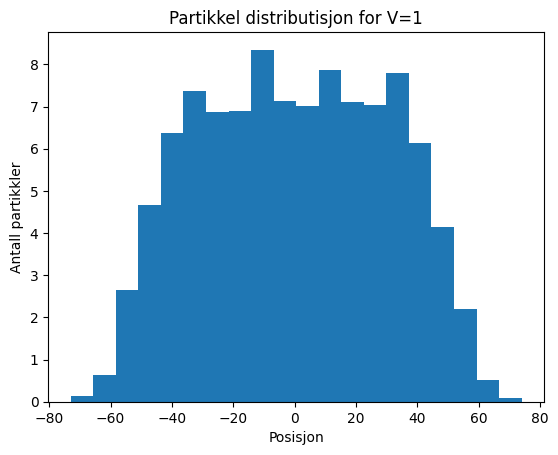

In [72]:

plt.figure("partikkel distributisjon")
plt.hist(posisjoner_ai,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V=1")
plt.xlabel("Posisjon")
plt.ylabel("Antall partikkler")
plt.show()

Når potensialet er konstant vil partiklene ha like stor sannsynlighet for bevegelse begge retninger. Et resultat av det er at sannsynlighetsfordelingen til en enkelt partikkel vil ligne en normalfordeling med forventningsverdi rundt startposisjonen dens. Summerer du disse sannsynlighetsfordelingene for alle partiklene spredt utover vil det ligne plottet vårt. Det blir en flat topp siden partiklene som ender i en posisjon stort sett bare er de som starter i umidelbar nærhet, og det er det samme for midten som litt lengre ut mot kanten( ikke på kanten).

 ii)

In [73]:
def V(x):
    return -x
start_pos=np.arange(-50,51,h)
posisjoner_aii= multiSim(100,start_pos,max_t,h,V)

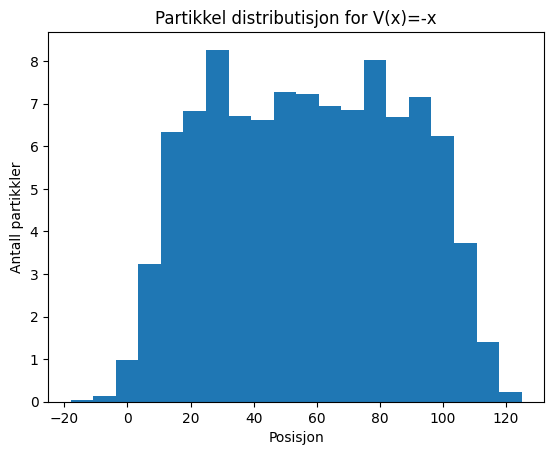

In [93]:
plt.figure("partikkel distributisjon")
plt.hist(posisjoner_aii,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V(x)=-x")
plt.xlabel("Posisjon")
plt.ylabel("Antall partikkler")
plt.show()

Fordelingen for $V(x) = x$ ligner veldig på fordelingen i 2ai, men vil i stede være sentrert rundt ca posisjon 60. Dette kommer av at når det er mer sannsynlig at partikkelen beveger seg mot høyre vil sannsynlighetsfordelingen til en enkelt partikkel hver sentrert rundt et punkt til høyre for startposisjonen sin avhengig av forskjellen mellom sannsynlighetene for å gå mot høyre og venstre. 

### Oppgave 2b

Må omdefinere random_step og simulation funksjonen for å inkludere partikkelinteraksjon ellers brukes den helt samme koden.

In [95]:
def random_step(XX,ind,h,V):
    r= rand.random()
    if (r<pm(XX[ind],V) and not((XX[ind]-h) in XX)): # Her inkluderes at partikkelen ikke ta samme posisjons verdi som en annen partikkel
        return -h
    elif (r>1-pp(XX[ind],V) and not((XX[ind]+h) in XX)):
        return h
    else:
        return 0

def simulation(start_pos,max_t,h,V):
    pos=np.array(start_pos)
    for i in range(0,max_t):
        for j in range(0,np.size(pos)):
            pos[j]=pos[j]+random_step(pos,j,h,V)
    return pos


i)

In [96]:
def V(x):
    return 1
start_pos=np.arange(-50,51,h)
posisjoner_bi= multiSim(100,start_pos,max_t,h,V)

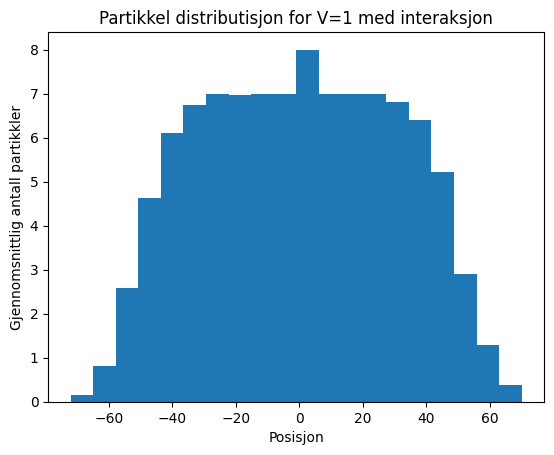

In [101]:

plt.figure("partikkel distributisjon")
plt.hist(posisjoner_bi,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V=1 med interaksjon")
plt.xlabel("Posisjon")
plt.ylabel("Gjennomsnittlig antall partikkler")
plt.show()

Ligner veldig på fordelingen i 2ai, men med partikkelinteraksjon blir fordelingen enda flatere på midten. Dette har med å gjøre at i motsetning til fordelingen uten partikkelinteraksjon skjer det faktisk veldig lite i midten. Uten partikkelinteraksjon var det at sannsynligheten bestemte at de fleste partiklene var fordelt i midten, med partikkelinteraksjon er det bare det at partiklene i midten ikke beveger seg. På kanten derimot oppfører det seg veldig lignende, siden der skjer det mindre partikkelinteraksjon etterhvert som partiklene spres litt. Dette sammen gjør at fordelingen i 2ai og 2bi blir veldig like, selv om det underliggende som skjer ikke er så likt.

Toppen rundt null er fordi det er 20 bins, så da velger bare histogramet et av binsene rundt null og legger partikkelen rundt null i. 

ii)

In [90]:
def V(x):
    return -x
start_pos=np.arange(-50,51,h)
posisjoner_bii= multiSim(100,start_pos,max_t,h,V)

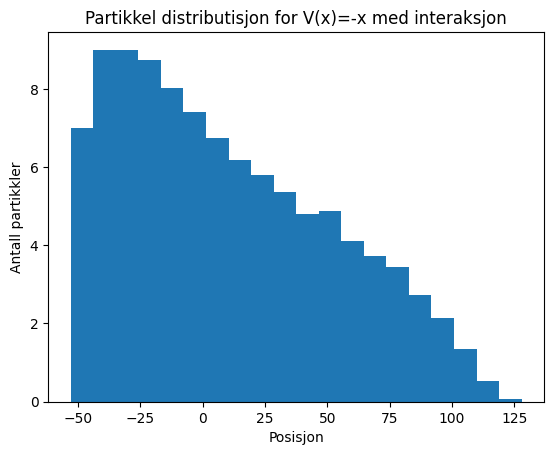

In [92]:
plt.figure("partikkel distributisjon")
plt.hist(posisjoner_bii,bins=20, weights= [1/100 for x in range(100*101)])
plt.title("Partikkel distributisjon for V(x)=-x med interaksjon")
plt.xlabel("Posisjon")
plt.ylabel("Antall partikkler")
plt.show()


Fordelingen for $V(x)=-x$ med partikkelinteraksjon, blir veldig ulik den med samme potensial men uten partikkelinteraksjon. Dette kommer av at partikkelen neste lengst mot høyre må vente et tidsteg før den kommer seg mot høyre siden den blir blokkert av den ytterste partikkelen, og videre selv blokkerer den innenfor seg i to tidsteg, osv innover. Dette gjør at partikkelene langt mot venstre ikke rekker å bevege seg, siden det er 101 partikler og bare 100 tidsteg. Hadde vi gjort simuleringen med flere tidsteg hadde til slutt fordelingen blitt ganske flat siden partiklene hadde kommet langt nok fra hverandre til at situasjonen ligner mer den i 2aii. 

### Oppgave 1c

For V konstant har temperatur ingenting å si fordi eksponential leddene uansett blir 1, og alle sannsynlighetene blir $\frac{1}{3}$. For V(x)=x vil lavere temperatur, altså høyere $\beta$ bety at eksponential leddene ha større betyding, så potensialet bestemmer i større grad hvor partiklene beveger seg. Det betyr at partiklene i 2a og 2b hadde kommet seg enda lengre i retning minste potensial. I både 2a og 2b ville fordelingen bli veldig flat, ettersom partiklene nesten alltid hadde beveget seg mot høyre, og dermed hadde endt opp nesten samme sted hver gang. Forskjellen hadde vært at fordelingen i 2b hadde fortsatt vært mer spredt av samme grunn som forklart i 2bii.